# Traffic Analysis and Prediction
## TrafficRush — Predicting High Traffic Conditions Using Machine Learning
**CSE3141 · Manipal University Jaipur**

Can weather, time, weekday and holidays help classify an hour as **High Traffic** or **Normal Traffic**? We use Binary Logistic Regression on real historical I-94 vehicle counts. High Traffic means volume at or above the training-period 70th percentile. It does **not** mean a jam, crash probability, individual vehicle movement, or a live traffic report.

This notebook follows the simple 20-cell airline reference inspected from `airlineprediction-main.zip`, with additional chronological validation and a weather ablation. The readable implementation is in `traffic_analysis.py`; this notebook presents each step, charts and results with short function calls. The CSE3141 handout was inspected: this project covers its data preparation, visualization, feature selection, binary logistic regression and model-validation topics; other syllabus algorithms are not added without a research need.

In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd() if (Path.cwd()/'traffic_analysis.py').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
import traffic_analysis as analysis

### 1. Collect the official UCI dataset
[Metro Interstate Traffic Volume, UCI 492](https://archive.ics.uci.edu/dataset/492/metro+interstate+traffic+volume)
contains hourly westbound I-94 traffic at ATR station 301, 2012–2018.
Temperature is Kelvin, rain/snow are mm per hour, clouds are percent, and timestamps
are local CST as documented by UCI. We preserve those local wall-clock labels
without guessing DST/UTC conversion. The official ZIP is cached and hashed locally.

In [2]:
raw = analysis.load_data()

Official source: https://archive.ics.uci.edu/static/public/492/metro%2Binterstate%2Btraffic%2Bvolume.zip
Local archive SHA-256: b99aeabcbd6cc86f642da3a79d90883425798f58abd3b3302da2fa19dda73768
Dataset shape: (48204, 9)


,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
0,NaN,288.28,0.0,0.0,40,Clouds,scattered clouds,2012-10-02 09:00:00,5545
1,NaN,289.36,0.0,0.0,75,Clouds,broken clouds,2012-10-02 10:00:00,4516
2,NaN,289.58,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 11:00:00,4767
3,NaN,290.13,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 12:00:00,5026
4,NaN,291.14,0.0,0.0,75,Clouds,broken clouds,2012-10-02 13:00:00,4918


,dtype
holiday,object
temp,float64
rain_1h,float64
snow_1h,float64
clouds_all,int64
weather_main,object
weather_description,object
date_time,object
traffic_volume,int64


Columns: ['holiday', 'temp', 'rain_1h', 'snow_1h', 'clouds_all', 'weather_main', 'weather_description', 'date_time', 'traffic_volume']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48204 entries, 0 to 48203
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   holiday              61 non-null     object 
 1   temp                 48204 non-null  float64
 2   rain_1h              48204 non-null  float64
 3   snow_1h              48204 non-null  float64
 4   clouds_all           48204 non-null  int64  
 5   weather_main         48204 non-null  object 
 6   weather_description  48204 non-null  object 
 7   date_time            48204 non-null  object 
 8   traffic_volume       48204 non-null  int64  
dtypes: float64(3), int64(2), object(4)
memory usage: 3.3+ MB


### 2. Data quality and one observation per hour
We check rather than assume the documented absence of missing values. Repeated
timestamps can reflect multiple weather descriptions for one traffic count.
For the main analysis, require agreement on volume and keep the **first source
weather record per hour**; this deterministic choice uses no target ranking and
prevents duplicated hours receiving extra weight. Conflicting-volume hours are
quarantined. Zero Kelvin is physically invalid and becomes missing for training-fit
imputation. Negative precipitation and out-of-range cloud cover are invalid.
IQR flags alone do not justify deleting unusual but nonnegative weather values.

In [3]:
df = analysis.clean_data(raw)

,missing
holiday,48143
temp,0
rain_1h,0
snow_1h,0
clouds_all,0
weather_main,0
weather_description,0
date_time,0
traffic_volume,0


Exact duplicate rows: 17


Extra records sharing an hour: 7612
Hours with conflicting volume: 0
Zero/nonpositive Kelvin readings: 10


,temp_c,rain_1h,snow_1h,clouds_all,traffic_volume
count,40565.000000,40575.000000,40575.000000,40575.000000,40575.000000
mean,8.236113,0.318632,0.000117,44.199162,3290.650474
std,13.093185,48.812640,0.005676,38.683447,1984.772909
min,-29.760000,0.000000,0.000000,0.000000,0.000000
25%,-1.300000,0.000000,0.000000,1.000000,1248.500000
50%,9.720000,0.000000,0.000000,40.000000,3427.000000
75%,19.130000,0.000000,0.000000,90.000000,4952.000000
max,36.920000,9831.300000,0.510000,100.000000,7280.000000


,IQR flags retained
temp_c,0
rain_1h,2054
snow_1h,31
traffic_volume,0


Largest rain measurements (mm): [9831.3, 55.63, 44.45]
Usable unique hours: 40575 Coverage: 2012-10-02 09:00:00 to 2018-09-30 23:00:00


### 3. Time features, chronological split and training-only target
Hour, weekday and month are **categorical** so Logistic Regression can learn
nonmonotonic rush-hour/seasonal patterns. Weekend is exactly determined by weekday;
we keep it for descriptive analysis and omit that redundant predictor from both
models. A holiday flag represents the known calendar day.

Split unique hours 70%/15%/15% chronologically, then define High Traffic using
**training volume only**. No volume, future count, timestamp ID or weather
description enters X. The probability decision threshold is fixed at 0.5.

In [4]:
parts, volume_threshold = analysis.split_data(df)
train = parts["train"]

,partition,hours,start,end,high_fraction
0,train,28402,2012-10-02 09:00:00,2017-05-10 04:00:00,0.300190
1,validation,6086,2017-05-10 05:00:00,2018-01-19 14:00:00,0.316957
2,test,6087,2018-01-19 15:00:00,2018-09-30 23:00:00,0.315426


High Traffic cutoff: 4722.0 vehicles/hour (training 70th percentile)


**Decision:** use ≥4,722 vehicles/hour as High Traffic in every partition and in the app. It is a historical count label, not a universal road-capacity limit.

### 4. Exploratory analysis on training hours
**Purpose:** examine the target distribution and hourly patterns without letting
test behavior guide feature decisions. The plots use one record per hour and
show descriptive means, not causal effects.

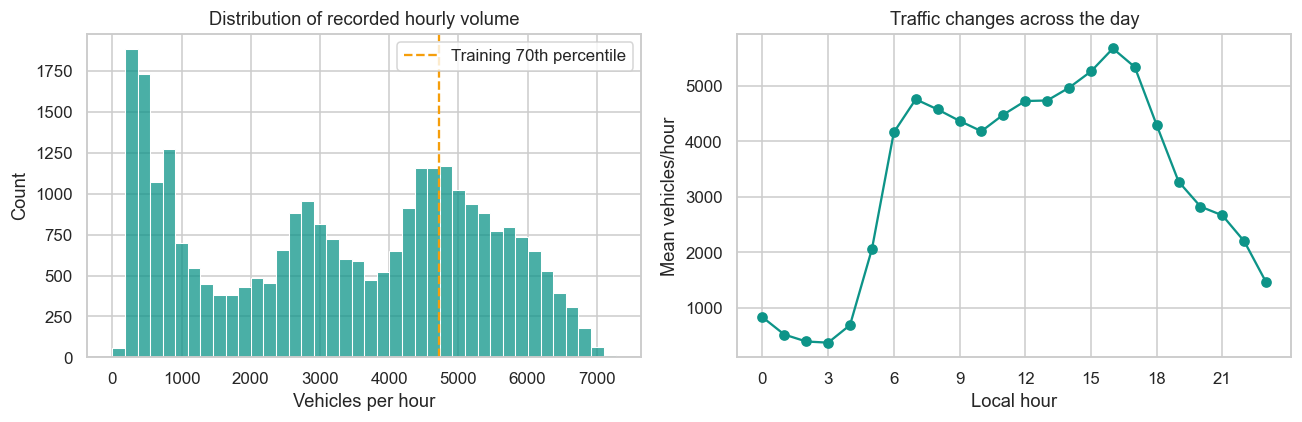

**Observed:** the largest training mean occurs at local hour 16:00. The full distribution separates low-volume and busy hours. **Decision:** encode hour categorically rather than force a straight-line increase from midnight to 23:00.

In [5]:
analysis.plot_volume(train, volume_threshold)

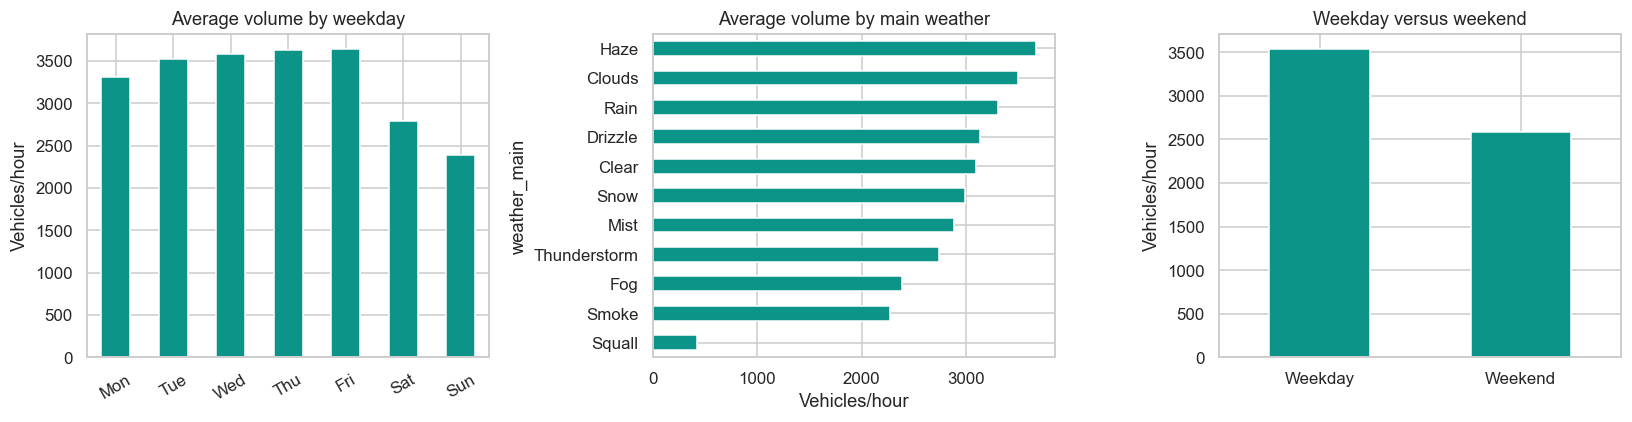

**Interpretation → decision:** day and weather groups have different observed means, but weather groups also occur at different times and have unequal sample sizes. Retain weekday and a compact weather group for the controlled feature comparison; do not treat these unadjusted differences as causal weather effects.

In [6]:
analysis.plot_calendar(train)

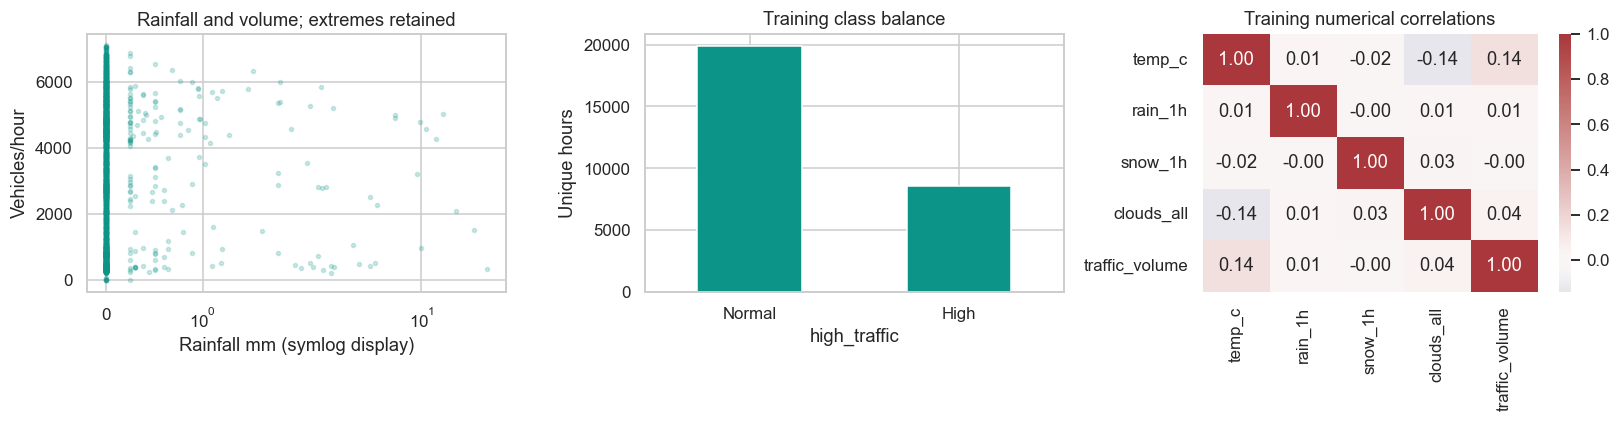

**Observed → decision:** precipitation is strongly skewed and simple weather–volume correlations do not isolate calendar effects. All nonnegative extreme measurements remain in this simple model; their plausibility and leverage are limitations. Imputation and scaling must fit training only, and actual validation determines regularization.

In [7]:
analysis.plot_weather(train)

### 5. Simple preprocessing and two feature groups
**A:** hour, weekday, month and holiday. **B (primary):** A plus Celsius temperature,
rain, snow, clouds and main weather. We exclude weather_description, raw date_time,
traffic_volume and high_traffic. Weekend is omitted because weekday already determines it.

The ColumnTransformer applies training-fit median imputation/scaling to numeric
features and most-frequent imputation/one-hot encoding to categoricals.
`handle_unknown='ignore'` permits unseen weather categories without refitting.
B is the predeclared primary weather-and-time model; A is the research ablation,
not a second algorithm. All input fields used by B are retained.

In [8]:
print("Primary features:", analysis.all_numeric + analysis.all_categorical)
print("Learned preprocessing is fitted inside each training pipeline.")

Primary features: ['is_holiday', 'temp_c', 'rain_1h', 'snow_1h', 'clouds_all', 'hour', 'day_of_week', 'month', 'weather_main']
Learned preprocessing is fitted inside each training pipeline.


### 6. Training and chronological validation
For binary Logistic Regression, p(High)=sigmoid(intercept + weighted encoded inputs).
The class is High when p≥0.5. L2 regularization shrinks coefficients; larger C
means less shrinkage. A small C grid {0.1, 1, 10} uses one predefined
**chronological validation fold**, not random cross-validation. Each pipeline
fits preprocessing only on the training portion. Validation selects C by F1.
No final test outcome is inspected during tuning; models remain training-fit
so training/validation/test scores describe the same estimator.

In [9]:
models, tuning = analysis.train_models(parts)
model = models["time_weather"]

,model,C,training_f1,validation_f1
0,time_only,0.1,0.865415,0.876281
1,time_only,1.0,0.868007,0.873262
2,time_only,10.0,0.867521,0.873033
3,time_weather,0.1,0.869212,0.876806
4,time_weather,1.0,0.869926,0.874280
5,time_weather,10.0,0.870056,0.873985


**Decision:** freeze the validation-selected C for each feature group and keep probability cutoff 0.5. The tuning table exposes train–validation gaps; a high training score alone would not establish future-period usefulness.

### 7. Final held-out evaluation and weather research experiment
Now evaluate both frozen Logistic Regression groups and a training-fit majority
baseline on the same chronological test hours. Accuracy, precision, recall, F1
and ROC-AUC measure different aspects. The experiment asks whether weather
actually improves F1/AUC beyond calendar information; a negative difference is
reported honestly. Validation is reused for C selection, so it is optimistic.

,partition,model,accuracy,precision,recall,f1,roc_auc
0,train,time_only,0.918492,0.857983,0.872977,0.865415,0.969374
1,train,time_weather,0.920639,0.860129,0.878489,0.869212,0.969817
2,validation,time_only,0.922609,0.888179,0.864697,0.876281,0.970492
3,validation,time_weather,0.922938,0.888711,0.865215,0.876806,0.972104
4,test,time_only,0.926401,0.882536,0.884375,0.883455,0.976077
5,test,time_weather,0.928372,0.884855,0.888542,0.886694,0.976986


accuracy     0.684574
precision    0.000000
recall       0.000000
f1           0.000000
roc_auc      0.500000
Name: majority baseline, dtype: float64

,precision,recall,f1-score,support
Normal Traffic,0.948545,0.946724,0.947634,4167.000000
High Traffic,0.884855,0.888542,0.886694,1920.000000
accuracy,0.928372,0.928372,0.928372,0.928372
macro avg,0.916700,0.917633,0.917164,6087.000000
weighted avg,0.928456,0.928372,0.928412,6087.000000


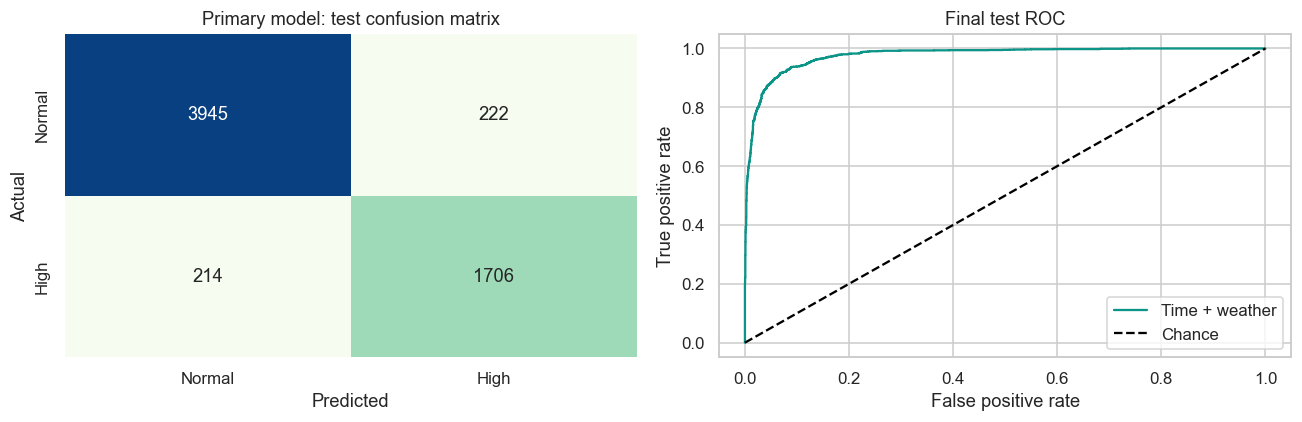

,partition,model,f1,roc_auc
2,validation,time_only,0.876281,0.970492
3,validation,time_weather,0.876806,0.972104
4,test,time_only,0.883455,0.976077
5,test,time_weather,0.886694,0.976986


**Actual findings:** primary test F1 0.887, AUC 0.977. Weather-minus-time F1 +0.003, AUC +0.001. These differences do not prove that weather causes changes in volume, and the test is not reused for tuning.

In [10]:
results = analysis.evaluate_models(models, parts)

### 8. Model interpretation
Encoded calendar/weather coefficients are associations with High Traffic log odds.
Numeric coefficients apply to a training-standard-deviation change; one-hot
coefficients are regularized effects relative to the encoded representation.
Correlated predictors and full one-hot encoding limit isolated interpretation.
A coefficient is not a causal effect or a universal traffic rule.

In [11]:
coefficients = analysis.interpret_model(model)

,feature,coefficient,magnitude
21,cat__hour_16,3.340242,3.340242
20,cat__hour_15,3.296828,3.296828
35,cat__day_of_week_6,-3.260060,3.260060
19,cat__hour_14,2.981770,2.981770
22,cat__hour_17,2.973724,2.973724
12,cat__hour_7,2.814785,2.814785
11,cat__hour_6,2.749515,2.749515
13,cat__hour_8,2.682400,2.682400
24,cat__hour_19,-2.604235,2.604235
25,cat__hour_20,-2.595926,2.595926


**Observed:** the largest standardized/encoded associations are cat__hour_16, cat__hour_15, cat__day_of_week_6, cat__hour_14, cat__hour_17. **Decision:** report their signs and conditional associations, without claiming causal feature importance.

### 9. Export the same fitted pipeline, real results and chart summaries
`traffic_analysis.py` exports the artifacts from the same fitted model. The backend loads this Joblib pipeline; it never retrains. Static dashboard JSON
contains genuine precomputed historical summaries and explicitly identifies its
scope. The frontend may read these saved summaries when the API is offline,
but it must never fabricate prediction probabilities. Three real held-out inputs
are exported to verify notebook/backend inference parity.

In [12]:
analysis.export_results(
    raw, df, parts, volume_threshold, model, tuning, results, coefficients
)

Exported fitted pipeline, actual metrics, summaries and parity cases.


### 10. Conclusion, literature background and limitations
Predictive analytics distinguishes descriptive traffic patterns from unseen-hour
classification. UCI originally supplies a regression target; we define a transparent
binary count label for a syllabus-aligned Logistic Regression experiment. Calendar
effects and weather associations are descriptive; no intervention study establishes
causal effects. Logistic Regression is an interpretable probabilistic classifier
rather than a traffic simulator.

The 2012–2018 scope is one westbound station. Repeated weather reports were reduced
to one source record per hour, potentially losing weather detail. Missing hours,
unusual weather values and changes across years limit transfer. The 70th percentile
is a training-defined label, not highway capacity. Measured same-hour weather is
assumed available; this is not an independently evaluated future-weather forecast.
Default 0.5 decisions and ranking AUC do not prove probability calibration.

References: Hogue, J. (2019), [Metro Interstate Traffic Volume](https://doi.org/10.24432/C5X60B),
UCI (CC BY 4.0); [scikit-learn Logistic Regression documentation](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html).
CSE3141 Predictive Analytics handout (local supplied course document). Future work:
additional stations/years, independent calibration and rolling-origin validation.

In [13]:
analysis.show_conclusion(raw, df, volume_threshold, results)

**Completed execution:** 48,204 source observations became 40,575 unique hours. High Traffic is ≥4,722 vehicles/hour. Test accuracy 92.84%, precision 0.885, recall 0.889, F1 0.887, AUC 0.977. Weather changes test F1 by +0.003 and AUC by +0.001. The same fitted pipeline and definition are exported for the website; results estimate historical volume categories, not jams or crashes.

All cells completed and artifact round-trip verified.
